# 03 · Task demands, energy budget and learning regime decide how much to mix

**Question 3 (continued).** Notebook 01 showed what *constraints* favour disentangling. Here we vary what the
*downstream readers* need. A population is read by many linear decoders (tasks). Tasks that are
**linear in the factors** can be solved by a factorised code; **nonlinear** tasks (XOR-like dichotomies
of factor conjunctions, Rigotti et al. 2013) require nonlinear mixed selectivity.

Prediction: the fraction of nonlinear-mixed neurons, the NMS index and the shattering dimensionality
grow with the number of nonlinear tasks, while disentanglement falls — and the energy budget sets
the exchange rate. CCGP (abstraction) may survive moderate mixing (Bernardi et al. 2020; Johnston & Fusi 2023).

Factors: A (3 levels) × B (3 levels) × context (2) = 18 conditions, embedded in 50 input channels with noise.

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


In [2]:
lev = (3, 3, 2); conds = data.discrete_conditions(lev)
Xc, _ = data.condition_embedding(conds, lev, D=50, kind="linear", seed=0)
LIN = data.linear_tasks(conds, lev)
NL_ALL = data.random_dichotomy_tasks(conds, 16, seed=1, levels=lev)
STEPS = 300 if FAST else 4000
SEEDS = [0] if FAST else [0, 1, 2]
H = 100
NPER = 20 if FAST else 40
def run(n_nl, act_l2=1e-2, init=0.5, seed=0, H=H):
    Y = LIN if n_nl == 0 else np.c_[LIN, NL_ALL[:, :n_nl]]
    rng = np.random.default_rng(seed)
    X, Yt, ci = data.trials_from_conditions(Xc, Y, NPER, noise=0.3, rng=rng)
    m = models.MultiTaskNet(50, H, Y.shape[1], init_scale=init, seed=seed)
    models.train(m, X, Yt, "bce", steps=STEPS, act_l2=act_l2, w_l2=1e-5, seed=seed)
    Xte, Yte, cte = data.trials_from_conditions(Xc, Y, NPER, noise=0.3, rng=np.random.default_rng(seed + 100))
    Z = models.hidden(m, Xte)
    cls, nms, _ = metrics.selectivity_discrete(Z, conds[cte])
    fr = metrics.class_fractions(cls)
    Cb = conds[cte].copy(); Cb[:, 0] = Cb[:, 0] >= 1; Cb[:, 1] = Cb[:, 1] >= 1   # binarised factors for CCGP
    return dict(acc=models.task_accuracy(m, Xte, Yte), nms=float(np.nanmean(nms)), **fr,
                SD=metrics.shattering_dim(Z, cte, n_dich=30 if FAST else 60),
                CCGP=float(np.nanmean([metrics.ccgp(Z, Cb, k) for k in range(3)])),
                disent=metrics.disentanglement(Z, conds[cte].astype(float), deg=2)[0],
                pr=metrics.participation_ratio(Z), **metrics.energy(Z))

## 1. Number of nonlinear tasks

n_nonlinear= 0 | acc 1.00 nonlinear_mixed 0.54 nms 0.14 disent 0.62 SD 0.81 CCGP 0.88 pr 3.68 mean_sq 0.12
n_nonlinear= 1 | acc 1.00 nonlinear_mixed 0.91 nms 0.27 disent 0.39 SD 0.99 CCGP 0.98 pr 7.21 mean_sq 0.16
n_nonlinear= 2 | acc 1.00 nonlinear_mixed 0.94 nms 0.29 disent 0.38 SD 0.99 CCGP 0.97 pr 7.97 mean_sq 0.19
n_nonlinear= 4 | acc 1.00 nonlinear_mixed 0.97 nms 0.31 disent 0.34 SD 1.00 CCGP 0.98 pr 9.43 mean_sq 0.23
n_nonlinear= 8 | acc 1.00 nonlinear_mixed 0.97 nms 0.35 disent 0.31 SD 1.00 CCGP 0.99 pr 10.88 mean_sq 0.29
n_nonlinear=16 | acc 1.00 nonlinear_mixed 1.00 nms 0.38 disent 0.31 SD 1.00 CCGP 0.99 pr 11.87 mean_sq 0.38


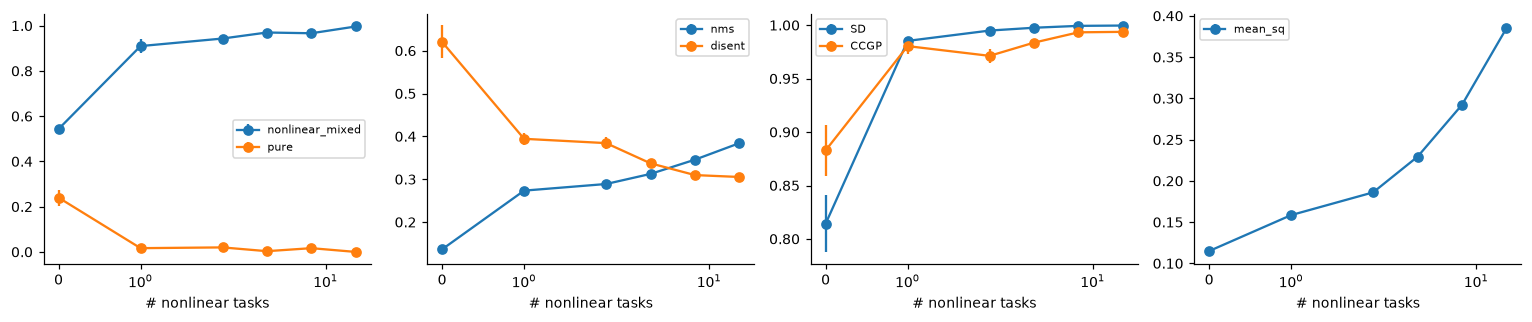

In [3]:
NNL = [0, 4] if FAST else [0, 1, 2, 4, 8, 16]
R1 = {(n, s): run(n, seed=s) for n in NNL for s in SEEDS}
KEYS = ["acc", "nonlinear_mixed", "nms", "disent", "SD", "CCGP", "pr", "mean_sq"]
for n in NNL:
    print(f"n_nonlinear={n:2d} | " + " ".join(f"{k} {np.nanmean([R1[(n, s)][k] for s in SEEDS]):.2f}" for k in KEYS))
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, ks in zip(axs, [["nonlinear_mixed", "pure"], ["nms", "disent"], ["SD", "CCGP"], ["mean_sq"]]):
    for k in ks:
        M = np.array([[R1[(n, s)][k] for s in SEEDS] for n in NNL])
        ax.errorbar(NNL, np.nanmean(M, 1), np.nanstd(M, 1), marker="o", label=k)
    ax.set_xlabel("# nonlinear tasks"); ax.legend(fontsize=7); ax.set_xscale("symlog")
plt.tight_layout(); savefig("03_task_nonlinearity"); plt.show()

**Result (3 seeds).** Task demands buy mixing:

| # nonlinear tasks | 0 | 1 | 2 | 4 | 8 | 16 |
|---|---|---|---|---|---|---|
| nonlinear-mixed fraction | 0.54 | 0.91 | 0.94 | 0.97 | 0.97 | 1.00 |
| NMS index | 0.14 | 0.27 | 0.29 | 0.31 | 0.35 | 0.38 |
| disentanglement | 0.62 | 0.39 | 0.38 | 0.34 | 0.31 | 0.31 |
| participation ratio | 3.7 | 7.2 | 8.0 | 9.4 | 10.9 | 11.9 |
| shattering dimensionality | 0.81 | 0.99 | 0.99 | 1.00 | 1.00 | 1.00 |
| CCGP | 0.88 | 0.98 | 0.97 | 0.98 | 0.99 | 0.99 |
| mean squared rate (energy) | 0.12 | 0.16 | 0.19 | 0.23 | 0.29 | 0.38 |

A single nonlinear task already makes > 90 % of neurons nonlinearly mixed. Mixing costs energy (3× from 0 to 16 tasks) and
dimensionality (3.2×), but **abstraction is not lost** (CCGP ≥ 0.97): learned mixing is structured, unlike random mixing (CCGP 0.35 in notebook 00).

## 2. Energy budget × task demands

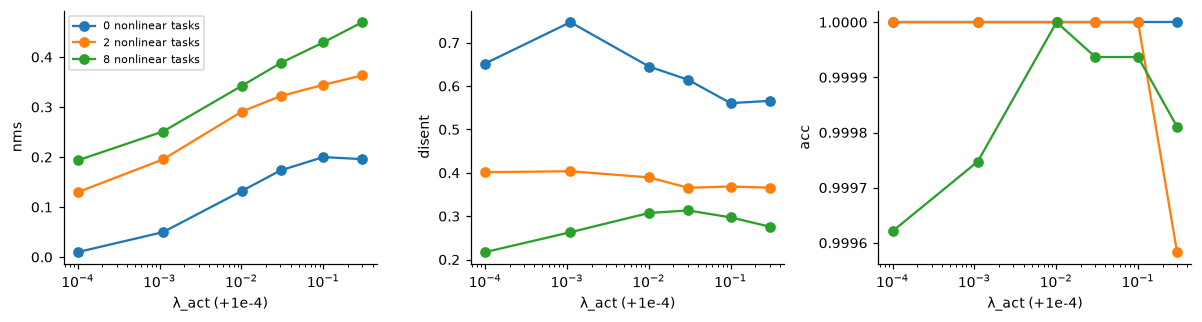

In [4]:
LAMS = [0.0, 0.1] if FAST else [0.0, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1]
NNL2 = [0, 4] if FAST else [0, 2, 8]
R2 = {(l, n, s): run(n, act_l2=l, seed=s) for l in LAMS for n in NNL2 for s in SEEDS[:2]}
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for n in NNL2:
    for ax, k in zip(axs, ["nms", "disent", "acc"]):
        ax.plot(np.array(LAMS) + 1e-4, [np.nanmean([R2[(l, n, s)][k] for s in SEEDS[:2]]) for l in LAMS], "-o", label=f"{n} nonlinear tasks")
        ax.set_xscale("log"); ax.set_xlabel("λ_act (+1e-4)"); ax.set_ylabel(k)
axs[0].legend(fontsize=7); plt.tight_layout(); savefig("03_energy_x_task"); plt.show()

**Result.** The activity cost has an effect opposite to notebook 01: with only linear tasks, raising λ from 0 to 0.3 *increases*
the nonlinear-mixed fraction from 0.01 to 0.78 (NMS 0.01 → 0.20) while disentanglement falls slightly (0.65 → 0.57), and energy
drops 70-fold. With nonlinear tasks the same trend holds (2 tasks: 0.69 → 0.97). An energy cost on ReLU units in a classification
network makes them **sparse and thresholded**: a unit that fires only when, say, A and B are both high is a conjunctive (nonlinearly
mixed) unit. So energy favours factorised codes when the readout must reconstruct continuous factors (notebook 01) but sparse
conjunctive codes when it must classify discrete conditions. Accuracy stays at 1.00 throughout.

## 3. Rich vs lazy learning
With a large initialisation (lazy regime) the hidden layer should barely change, so mixing would be inherited from random weights and be
task-independent; with a small initialisation (rich regime) mixing should track task demands.

**Result (as implemented, Adam optimiser).** Task demands dominate at every initialisation: with 16 nonlinear tasks the nonlinear-mixed
fraction is 0.92–0.99 and disentanglement 0.28–0.34 for all scales. With linear tasks only, the largest initialisation (3.0) keeps more
random mixing (nonlinear-mixed 0.54 vs 0.18–0.29; NMS 0.15 vs 0.05–0.07) — the expected lazy signature, but small. Adam rescales updates
and partly removes the lazy regime; a definitive test needs plain SGD with NTK-style scaling and wider layers.

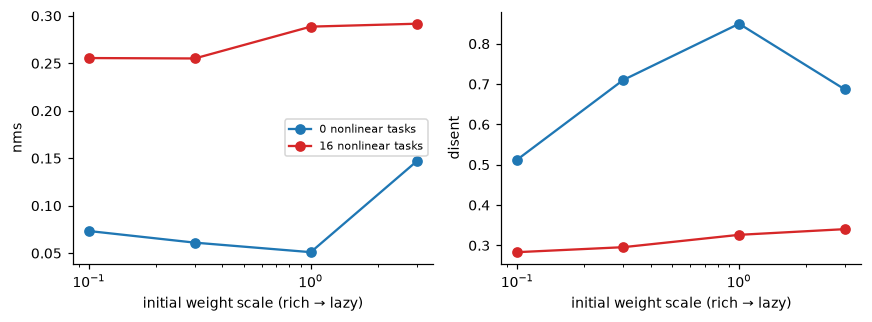

saved


In [5]:
INITS = [0.2, 3.0] if FAST else [0.1, 0.3, 1.0, 3.0]
R3 = {(i, n, s): run(n, init=i, seed=s, act_l2=1e-3) for i in INITS for n in [0, NNL[-1]] for s in SEEDS[:2]}
fig, axs = plt.subplots(1, 2, figsize=(8, 3))
for n, c in [(0, "tab:blue"), (NNL[-1], "tab:red")]:
    for ax, k in zip(axs, ["nms", "disent"]):
        ax.plot(INITS, [np.nanmean([R3[(i, n, s)][k] for s in SEEDS[:2]]) for i in INITS], "-o", color=c, label=f"{n} nonlinear tasks")
        ax.set_xscale("log"); ax.set_xlabel("initial weight scale (rich → lazy)"); ax.set_ylabel(k)
axs[0].legend(fontsize=7); plt.tight_layout(); savefig("03_rich_vs_lazy"); plt.show()
save_json({"R1": {f"{k[0]}|{k[1]}": v for k, v in R1.items()}, "NNL": NNL,
           "R2": {f"{k[0]}|{k[1]}|{k[2]}": v for k, v in R2.items()}, "LAMS": LAMS, "NNL2": NNL2,
           "R3": {f"{k[0]}|{k[1]}|{k[2]}": v for k, v in R3.items()}, "INITS": INITS},
          os.path.join(RES, "nb03_task_demands.json")); print("saved")

### Summary of notebook 03
* Nonlinear readout demands are the strongest driver of mixing (0.54 → 1.00 nonlinear-mixed; disentanglement 0.62 → 0.31), at a cost in
  energy (×3) and dimensionality (×3.2) but not in abstraction (CCGP ≈ 0.98).
* An activity-energy cost on classification networks produces **sparse conjunctive** units (nonlinear-mixed 0.01 → 0.78 with linear tasks only):
  whether energy favours factorised or mixed codes depends on the readout (reconstruction vs classification).
* The learning-regime test is inconclusive as implemented (Adam); only a weak lazy signature with linear tasks.